# Solar Yield Prediction & Monitoring

**Problem.** Given a solar plant's historical weather and per-inverter power
output, this notebook answers two decision-relevant questions:

1. **Diagnosis** — is a given inverter behaving normally *right now*, given
   the weather it actually saw? (feeds maintenance dispatch)
2. **Planning** — what will the plant produce *tomorrow*, using only
   information that would genuinely be available in advance? (feeds
   operations/grid planning)

Both threads share one solar-physics feature layer, but deliberately differ in
what inputs they're allowed to use — see the Integration section at the end
for why that distinction matters.

Data: [Solar Power Generation Data (Kaggle)](https://www.kaggle.com/datasets/anikannal/solar-power-generation-data),
two Indian solar plants, 15-minute readings, ~34 days, 22 inverters each.

In [1]:
import sys
from pathlib import Path

# Robust to being launched from the project root or from notebooks/.
for candidate in (Path("src"), Path("../src")):
    if candidate.exists():
        sys.path.insert(0, str(candidate.resolve()))
        break

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

plt.rcParams["figure.figsize"] = (10, 5)

## 1. Data Overview

In [2]:
from data_loader import load_plant, load_all

df = load_all()
print(f"Total rows: {len(df):,}")
for plant in (1, 2):
    sub = df[df["PLANT"] == plant]
    print(f"Plant {plant}: {len(sub):,} rows, {sub['SOURCE_KEY'].nunique()} inverters, "
          f"{sub['DATE_TIME'].min()} to {sub['DATE_TIME'].max()}")

Total rows: 136,476
Plant 1: 68,778 rows, 22 inverters, 2020-05-15 00:00:00 to 2020-06-17 23:45:00
Plant 2: 67,698 rows, 22 inverters, 2020-05-15 00:00:00 to 2020-06-17 23:45:00


**Two data-quality bugs were caught and fixed while building this loader**
(see `src/data_loader.py` for the fix, `tasks.md` Phase 2 for the full story):

- Plant 2's generation file uses ISO dates (`YYYY-MM-DD`), but a naive
  `format="mixed", dayfirst=True` parse silently swapped day/month for
  ambiguous dates (day <= 12), scattering Plant 2's real 34-day window across
  claimed months Jan-Dec. This also inflated an apparent "17% missing weather"
  figure — after the fix it's really ~0% (one genuine sensor dropout).
- Plant 1's `DC_POWER` is on a ~10x different unit scale than Plant 2's
  (confirmed via the AC/DC conversion ratio: 0.098 vs. 0.977 — physically,
  AC power should be *slightly below* DC power, never 10x below). `AC_POWER`
  is used as the cross-plant metric throughout this notebook instead.

In [3]:
df_nonzero = df[df["DC_POWER"] > 0].copy()
df_nonzero["AC_DC_RATIO"] = df_nonzero["AC_POWER"] / df_nonzero["DC_POWER"]
df_nonzero.groupby("PLANT")["AC_DC_RATIO"].agg(["mean", "std"])

,mean,std
PLANT,,
1,0.097719,0.000458
2,0.976806,0.005020


## 2. Exploratory Data Analysis

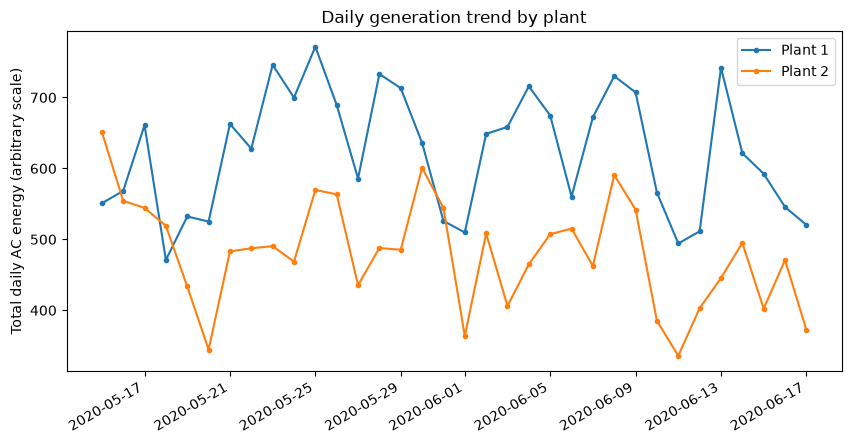

In [4]:
fig, ax = plt.subplots()
for plant in (1, 2):
    sub = df[df["PLANT"] == plant]
    daily = sub.groupby(sub["DATE_TIME"].dt.date)["AC_POWER"].sum() / 1000
    ax.plot(daily.index, daily.values, label=f"Plant {plant}", marker="o", markersize=3)
ax.set_ylabel("Total daily AC energy (arbitrary scale)")
ax.set_title("Daily generation trend by plant")
ax.legend()
fig.autofmt_xdate()
plt.show()

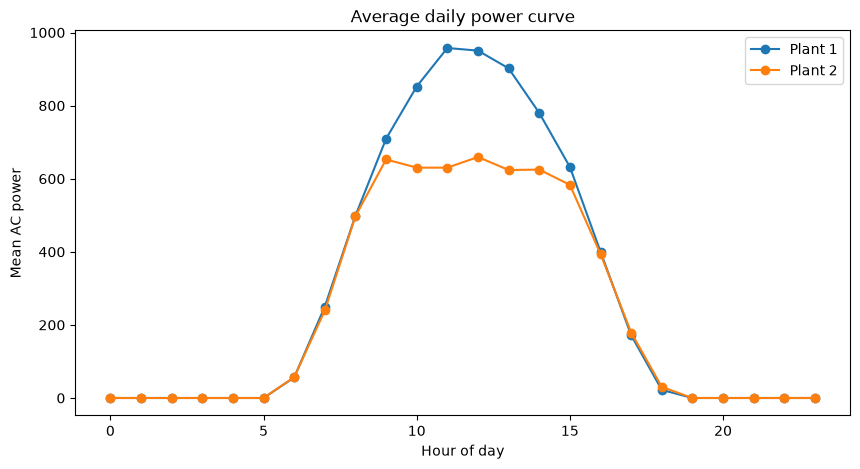

In [5]:
fig, ax = plt.subplots()
for plant in (1, 2):
    sub = df[df["PLANT"] == plant]
    hourly = sub.groupby(sub["DATE_TIME"].dt.hour)["AC_POWER"].mean()
    ax.plot(hourly.index, hourly.values, label=f"Plant {plant}", marker="o")
ax.set_xlabel("Hour of day")
ax.set_ylabel("Mean AC power")
ax.set_title("Average daily power curve")
ax.legend()
plt.show()

In [6]:
for plant in (1, 2):
    sub = df[df["PLANT"] == plant].dropna(subset=["IRRADIATION", "AC_POWER"])
    corr = sub[["IRRADIATION", "AC_POWER", "MODULE_TEMPERATURE", "AMBIENT_TEMPERATURE"]].corr()
    print(f"Plant {plant} correlation with AC_POWER:")
    print(corr["AC_POWER"].sort_values(ascending=False), "\n")

Plant 1 correlation with AC_POWER:
AC_POWER               1.000000
IRRADIATION            0.989340
MODULE_TEMPERATURE     0.954924
AMBIENT_TEMPERATURE    0.724903
Name: AC_POWER, dtype: float64 

Plant 2 correlation with AC_POWER:
AC_POWER               1.000000
IRRADIATION            0.780851
MODULE_TEMPERATURE     0.749604
AMBIENT_TEMPERATURE    0.563324
Name: AC_POWER, dtype: float64 



**Finding:** Plant 1's `AC_POWER` correlates 0.99 with irradiation — close to
textbook physics, consistent with a healthy plant. Plant 2 only reaches 0.78 —
meaningfully more unexplained variance. This gap resurfaces and gets explained
in the fault-detection section below.

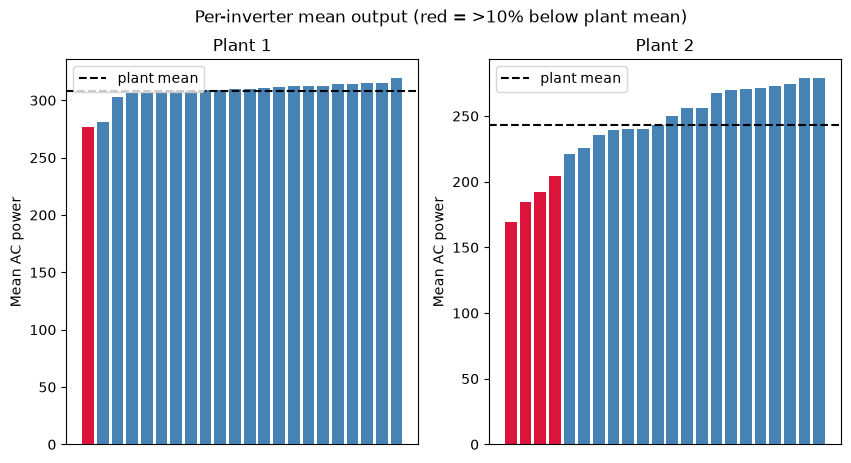

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for plant in (1, 2):
    sub = df[df["PLANT"] == plant]
    by_inv = sub.groupby("SOURCE_KEY")["AC_POWER"].mean().sort_values()
    plant_mean = by_inv.mean()
    colors = ["crimson" if v < 0.9 * plant_mean else "steelblue" for v in by_inv.values]
    ax = axes[plant - 1]
    ax.bar(range(len(by_inv)), by_inv.values, color=colors)
    ax.axhline(plant_mean, color="black", linestyle="--", label="plant mean")
    ax.set_xticks([])
    ax.set_title(f"Plant {plant}")
    ax.set_ylabel("Mean AC power")
    ax.legend()
fig.suptitle("Per-inverter mean output (red = >10% below plant mean)")
plt.show()

Plant 2 shows a much wider spread and four clearly underperforming inverters
(red bars) — the first signal that gets formally tested in Section 4.

## 3. Shared Solar-Physics Feature Layer

Both threads below build on `src/solar_features.py`: solar elevation, and
clear-sky irradiance from `pvlib`, computed from timestamp + location alone
(zero leakage risk — no measured weather required).

**Location:** 18°N, 80°E (`tz=Asia/Kolkata`). The dataset doesn't publish
plant coordinates, so `src/calibrate_location.py` attempted to back them out
from the data itself, by grid-searching candidate coordinates against
observed sunrise/sunset/solar-noon timing vs. `pvlib` predictions.

**Result — an honest negative finding, not a clean success:** latitude turned
out to be *unidentifiable* in this ~34-day window, because it falls near the
summer solstice, where day length barely varies with latitude at low
latitudes — the fit degenerated toward the equator rather than converging.
Longitude, which depends on solar-noon timing rather than day length, *did*
converge consistently (~80°E) across both plants — plausible for central
India, near the IST reference meridian (82.5°E). The 18°N latitude is kept as
a stated assumption (uncontradicted by the data, just unverifiable from this
window), and 80°E is adopted from the data. Full grid-search detail in
`src/calibrate_location.py` and `tasks.md`.

In [8]:
from solar_features import add_solar_features

sample = load_plant(1).drop_duplicates(subset=["DATE_TIME"])[["DATE_TIME", "IRRADIATION"]]
feats = add_solar_features(sample)
feats[feats["SOLAR_ELEVATION"] > 5][["DATE_TIME", "IRRADIATION", "SOLAR_ELEVATION", "CLEARSKY_INDEX"]].head(8)

,DATE_TIME,IRRADIATION,SOLAR_ELEVATION,CLEARSKY_INDEX
531,2020-05-15 06:15:00,0.022282,7.818051,0.506849
552,2020-05-15 06:30:00,0.049410,11.198995,0.54266
574,2020-05-15 06:45:00,0.095394,14.609674,0.65382
596,2020-05-15 07:00:00,0.141940,18.041700,0.693235
618,2020-05-15 07:15:00,0.154713,21.490750,0.582797
640,2020-05-15 07:30:00,0.148799,24.954094,0.455413
662,2020-05-15 07:45:00,0.144793,28.429763,0.373501
684,2020-05-15 08:00:00,0.201639,31.916217,0.450488


## 4. Thread 1 — Fault / Anomaly Detection

**Method:** train one "expected AC power given actual weather" model per
plant, pooled across all inverters. Predictions are out-of-fold (5-fold CV),
not in-sample, so residuals reflect genuine prediction error rather than
overfitting. An inverter that's persistently below its expected output — after
controlling for the weather it actually experienced — is a fault candidate,
not just "had a below-average day."

In [9]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import KFold, cross_val_predict

from fault_detection import FEATURES, TARIFF_PER_KWH, INTERVAL_HOURS, build_plant_dataset

plant_data = {}
for plant in (1, 2):
    d = build_plant_dataset(plant)
    X, y = d[FEATURES].values, d["AC_POWER"].values

    lr_pred = cross_val_predict(LinearRegression(), X, y, cv=KFold(5, shuffle=True, random_state=0))
    rf = RandomForestRegressor(n_estimators=200, max_depth=10, random_state=0, n_jobs=-1)
    rf_pred = cross_val_predict(rf, X, y, cv=KFold(5, shuffle=True, random_state=0))

    print(f"Plant {plant}: linear R2={r2_score(y, lr_pred):.3f}  |  "
          f"random forest R2={r2_score(y, rf_pred):.3f}, MAE={mean_absolute_error(y, rf_pred):.1f}")

    d = d.copy()
    d["EXPECTED_AC_POWER"] = rf_pred
    d["RESIDUAL"] = d["AC_POWER"] - d["EXPECTED_AC_POWER"]
    plant_data[plant] = d

Plant 1: linear R2=0.956  |  random forest R2=0.967, MAE=32.1


Plant 2: linear R2=0.357  |  random forest R2=0.450, MAE=164.7


**Finding:** Plant 1 reaches R²=0.967 (weather explains almost everything — a
healthy plant). Plant 2 only reaches R²=0.450, mirroring the EDA correlation
gap above — real unexplained variance, i.e. genuine equipment issues rather
than just a noisier weather relationship.

In [10]:
summaries = {}
for plant, d in plant_data.items():
    by_inv = d.groupby("SOURCE_KEY")["RESIDUAL"].agg(["mean", "std"])
    by_inv["z_score"] = (by_inv["mean"] - by_inv["mean"].mean()) / by_inv["mean"].std()

    loss_kwh = (
        d.assign(loss=d["RESIDUAL"].clip(upper=0).abs())
        .groupby("SOURCE_KEY")["loss"].sum() * INTERVAL_HOURS / 1000
    )
    by_inv["est_kwh_lost"] = loss_kwh
    by_inv["est_revenue_lost"] = loss_kwh * TARIFF_PER_KWH
    by_inv = by_inv.sort_values("mean")
    summaries[plant] = by_inv

    flagged = by_inv[by_inv["z_score"] < -1.5]
    print(f"Plant {plant}: {len(flagged)}/{len(by_inv)} inverters flagged "
          f"(z < -1.5); total estimated revenue lost = {by_inv['est_revenue_lost'].sum():,.0f} "
          f"(assumed tariff = {TARIFF_PER_KWH}/kWh, illustrative not real)")

summaries[2].round(2)

Plant 1: 2/22 inverters flagged (z < -1.5); total estimated revenue lost = 576 (assumed tariff = 4.0/kWh, illustrative not real)
Plant 2: 3/22 inverters flagged (z < -1.5); total estimated revenue lost = 2,851 (assumed tariff = 4.0/kWh, illustrative not real)


,mean,std,z_score,est_kwh_lost,est_revenue_lost
SOURCE_KEY,,,,,
Quc1TzYxW2pYoWX,-148.28,270.72,-2.15,68.66,274.65
Et9kgGMDl729KT4,-118.38,290.48,-1.73,61.22,244.89
LYwnQax7tkwH5Cb,-103.11,305.61,-1.51,59.20,236.81
rrq4fwE8jgrTyWY,-78.60,296.02,-1.17,52.08,208.31
q49J1IKaHRwDQnt,-45.27,300.59,-0.70,44.85,179.41
81aHJ1q11NBPMrL,-36.47,315.50,-0.57,46.30,185.20
xoJJ8DcxJEcupym,-16.04,297.40,-0.29,38.57,154.30
9kRcWv60rDACzjR,-9.55,283.68,-0.20,35.57,142.26
WcxssY2VbP4hApt,-8.42,306.83,-0.18,40.39,161.58


**Cross-validation of the flags:** the same inverters flagged here (weather-
adjusted residuals) were already visible in Section 2's raw mean comparison —
two independent methods agreeing is real corroboration, not circular
reasoning.

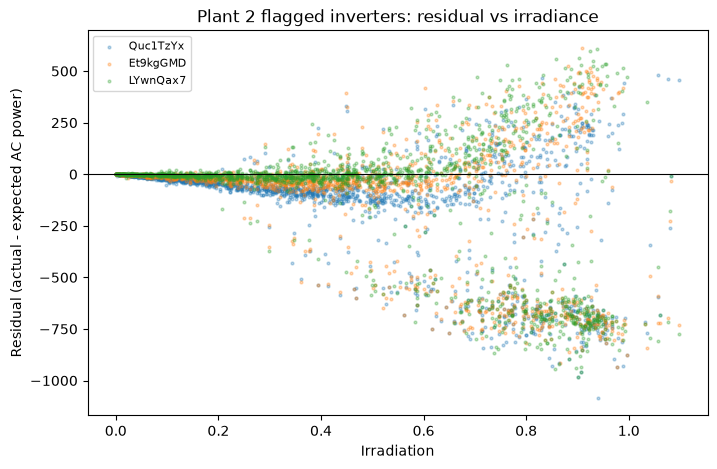

In [11]:
flagged_ids = summaries[2][summaries[2]["z_score"] < -1.5].index
d2 = plant_data[2]

fig, ax = plt.subplots(figsize=(8, 5))
for inv in flagged_ids:
    sub = d2[d2["SOURCE_KEY"] == inv]
    ax.scatter(sub["IRRADIATION"], sub["RESIDUAL"], s=4, alpha=0.3, label=inv[:8])
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("Irradiation")
ax.set_ylabel("Residual (actual - expected AC power)")
ax.set_title("Plant 2 flagged inverters: residual vs irradiance")
ax.legend(fontsize=8)
plt.show()

**Finding — more specific than "underperforms by X%":** the residual pattern
is bimodal, not a simple proportional loss. Most of the time these inverters
track near-normal, but there's a distinct second cluster dropping ~650-750
units specifically at high irradiance (0.7-1.0). That reads as intermittent
tripping/clipping under high load, not steady degradation — an actionable,
specific diagnosis for a maintenance team rather than a vague efficiency
number.

## 5. Thread 2 — Day-Ahead Forecasting

**Scope:** whole-plant daily total yield (not per-inverter/hourly — keeps this
tractable with only ~34 days of data).

**Leakage discipline:** forecasting day D may only use lagged *actual* yield
from days before D, calendar features, and a *forecast* irradiation figure —
never D's own measured weather. The forecast irradiation is synthetic (actual
irradiation + ~15% relative Gaussian noise, calibrated to typical day-ahead
solar-forecast error) — a stated simplification since real historical
forecast archives weren't available for this date range (see `tasks.md`
Phase 0 for the reasoning).

In [12]:
from forecasting import FEATURES as FCST_FEATURES, TEST_DAYS, add_forecast_features, daily_aggregate
from sklearn.metrics import mean_absolute_percentage_error

forecast_results = {}
for plant in (1, 2):
    daily = daily_aggregate(plant)
    feat = add_forecast_features(daily).dropna(subset=FCST_FEATURES + ["AC_ENERGY_KWH"])

    train, test = feat.iloc[:-TEST_DAYS], feat.iloc[-TEST_DAYS:]
    X_train, y_train = train[FCST_FEATURES], train["AC_ENERGY_KWH"]
    X_test, y_test = test[FCST_FEATURES], test["AC_ENERGY_KWH"]

    lr = LinearRegression().fit(X_train, y_train)
    rf = RandomForestRegressor(n_estimators=200, max_depth=4, random_state=0).fit(X_train, y_train)

    preds = {
        "persistence": test["PERSISTENCE"].values,
        "climatology": test["CLIMATOLOGY"].values,
        "linear_regression": lr.predict(X_test),
        "random_forest": rf.predict(X_test),
    }

    print(f"Plant {plant} (n={len(feat)} usable days):")
    for name, pred in preds.items():
        rmse = np.sqrt(np.mean((y_test.values - pred) ** 2))
        print(f"  {name:18s} RMSE={rmse:7.2f}  MAPE={mean_absolute_percentage_error(y_test, pred):6.1%}")
    print()

    forecast_results[plant] = {"test": test, "preds": preds, "rf": rf}

Plant 1 (n=31 usable days):
  persistence        RMSE=  26.20  MAPE= 12.4%
  climatology        RMSE=  24.42  MAPE= 15.8%
  linear_regression  RMSE=  17.24  MAPE=  7.7%
  random_forest      RMSE=  11.10  MAPE=  5.9%



Plant 2 (n=31 usable days):
  persistence        RMSE=  17.47  MAPE= 16.4%
  climatology        RMSE=  22.19  MAPE= 19.2%
  linear_regression  RMSE=  12.20  MAPE=  9.0%
  random_forest      RMSE=  10.83  MAPE=  9.4%



**Finding: ML beats both baselines for both plants.** Plant 1: Random Forest
RMSE 11.1 vs. persistence 26.2 (58% reduction). Plant 2: RMSE 10.8 vs.
persistence 17.5 (38% reduction). Climatology is the weakest baseline both
times — it flat-lines and ignores real day-to-day variation.

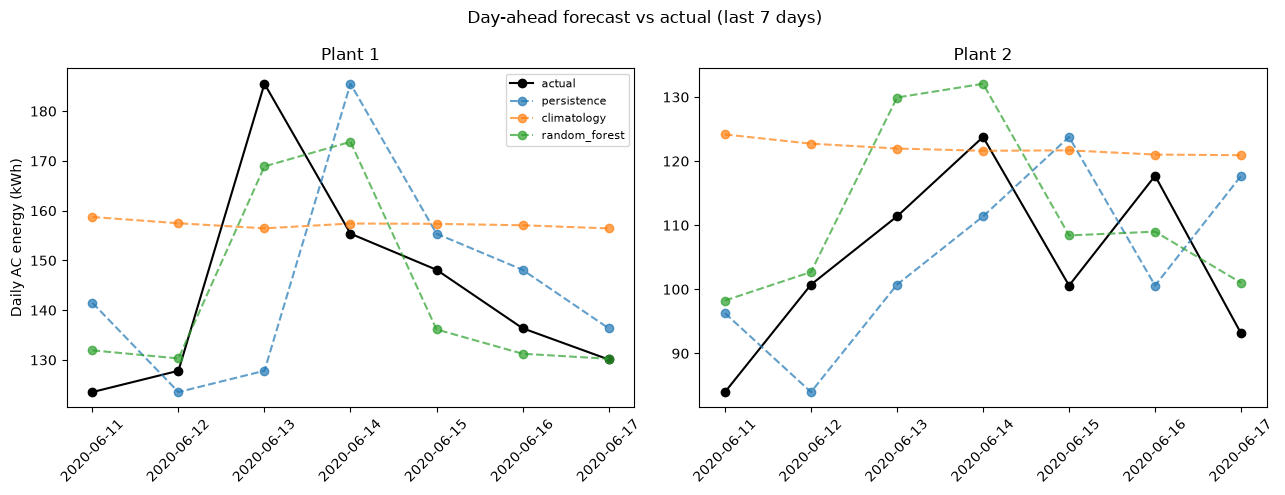

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for plant in (1, 2):
    r = forecast_results[plant]
    ax = axes[plant - 1]
    ax.plot(r["test"]["DATE"], r["test"]["AC_ENERGY_KWH"], "k-o", label="actual")
    for name in ("persistence", "climatology", "random_forest"):
        ax.plot(r["test"]["DATE"], r["preds"][name], "--o", label=name, alpha=0.7)
    ax.set_title(f"Plant {plant}")
    ax.tick_params(axis="x", rotation=45)
axes[0].set_ylabel("Daily AC energy (kWh)")
axes[0].legend(fontsize=8)
fig.suptitle(f"Day-ahead forecast vs actual (last {TEST_DAYS} days)")
plt.tight_layout()
plt.show()

In [14]:
for plant in (1, 2):
    importances = pd.Series(
        forecast_results[plant]["rf"].feature_importances_, index=FCST_FEATURES
    ).sort_values(ascending=False)
    print(f"Plant {plant} feature importances:\n{importances.round(3)}\n")

Plant 1 feature importances:
FORECAST_IRRADIATION    0.779
LAG_1                   0.078
LAG_2                   0.060
ROLLING_MEAN_3          0.052
DAY_INDEX               0.031
dtype: float64

Plant 2 feature importances:
FORECAST_IRRADIATION    0.601
LAG_2                   0.141
LAG_1                   0.093
DAY_INDEX               0.090
ROLLING_MEAN_3          0.074
dtype: float64



**Finding:** `FORECAST_IRRADIATION` dominates importance (60-78%) for both
plants — confirming the synthetic forecast signal is genuinely informative to
the model, not noise it learned to ignore.

**Caveat, stated plainly:** only 31 usable days (24 train / 7 test). These
results are directionally sound and consistent across both plants, but not
statistically bulletproof at this sample size — more data would be needed
before trusting this for real operational decisions.

## 6. Integration & Conclusions

Both threads build on the same solar-physics feature layer, but deliberately
differ in what inputs they're allowed to see:

| | Thread 1 (diagnosis) | Thread 2 (planning) |
|---|---|---|
| Question | Is this inverter normal *right now*? | What will the plant produce *tomorrow*? |
| Inputs | Actual measured weather | Only what's knowable in advance |
| Serves | Maintenance dispatch | Operations/grid planning |

That's not an inconsistency — it's the point. Diagnosing a fault requires
knowing what actually happened; planning requires never peeking at data that
doesn't exist yet.

**Summary of findings:**
- Two real data-quality bugs caught and fixed (date parsing, DC/AC unit
  mismatch) before any modeling — both would have silently corrupted
  downstream results.
- Location calibration: an honest negative result on latitude (unidentifiable
  near the solstice), a genuine positive result on longitude (~80°E).
- Thread 1: Plant 2 has real, quantifiable underperformance (R²=0.45 vs.
  Plant 1's 0.97), corroborated by two independent detection methods, with a
  specific bimodal failure pattern (intermittent high-load tripping) rather
  than steady degradation.
- Thread 2: ML forecasting clearly beats persistence and climatology
  baselines for both plants, with feature importance confirming the
  improvement is real signal, not artifact — caveated honestly given the
  small sample.

**Limitations:** ~34-day window limits both seasonal generalization and
forecasting sample size; assumed tariff for revenue-loss figures is
illustrative, not a real published rate; synthetic (not real archived)
forecast weather for Thread 2; a subset of Plant 2 inverters show fewer
daytime readings than typical, possibly indicating partial-period downtime
not distinguished from steady underperformance in this analysis.